In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, precision_recall_curve,
                             roc_curve, f1_score)

In [87]:
df = pd.read_csv("Churn_Modelling.csv")
print(df.shape)
print(df.head())
print(df.info())

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64
Geography
France     0.161548
Germany    0.324432
Spain      0.166734
Name: Exited, dtype: float64
Gender
Female    0.250715
Male      0.164559
Name: Exited, dtype: float64
NumOfProducts
1    0.277144
2    0.075817
3    0.827068
4    1.000000
Name: Exited, dtype: float64
IsActiveMember
0    0.268509
1    0.142691
Name: Exited, dtype: float64


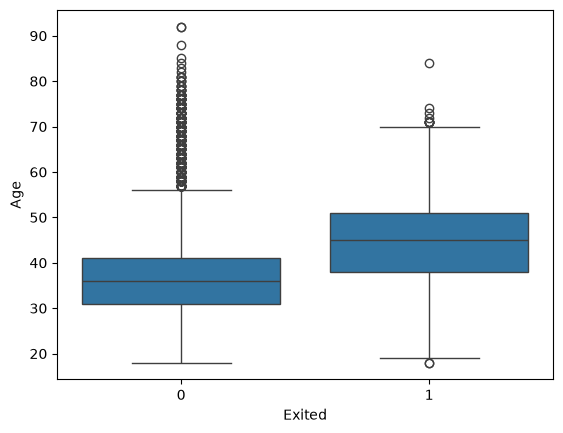

In [88]:
print(df.isnull().sum())                       # missing values
print(df["Exited"].value_counts(normalize=True))

# Churn rate by category
print(df.groupby("Geography")["Exited"].mean())
print(df.groupby("Gender")["Exited"].mean())
print(df.groupby("NumOfProducts")["Exited"].mean())
print(df.groupby("IsActiveMember")["Exited"].mean())

# Age vs churn
sns.boxplot(x="Exited", y="Age", data=df)
plt.show()

In [89]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["IsZeroBalance"] = (df["Balance"] == 0).astype(int)
df["AgeTenureRatio"] = df["Tenure"] / df["Age"]
df["ProductsPerTenure"] = df["NumOfProducts"] / (df["Tenure"] + 1)
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
cat_cols = ["Geography", "Gender"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=10,
                                       min_samples_leaf=5,
                                       class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocess),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                               max_depth=4,
                                               class_weight="balanced",
                                               random_state=42))
    ]),
}

(8000, 14) (2000, 14)


In [90]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)
    print(f"{name}: ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: ROC-AUC = 0.766 (+/- 0.021)
Random Forest: ROC-AUC = 0.857 (+/- 0.011)
Gradient Boosting: ROC-AUC = 0.862 (+/- 0.011)


In [91]:
rows = []
probas = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    probas[name] = proba
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
print(results.to_string(index=False))

              Model  ROC-AUC  PR-AUC    F1
Logistic Regression    0.775   0.466 0.502
      Random Forest    0.866   0.703 0.621
  Gradient Boosting    0.866   0.715 0.610


Best model: Random Forest
              precision    recall  f1-score   support

      Stayed       0.92      0.87      0.89      1593
     Churned       0.57      0.69      0.62       407

    accuracy                           0.83      2000
   macro avg       0.74      0.78      0.76      2000
weighted avg       0.84      0.83      0.84      2000



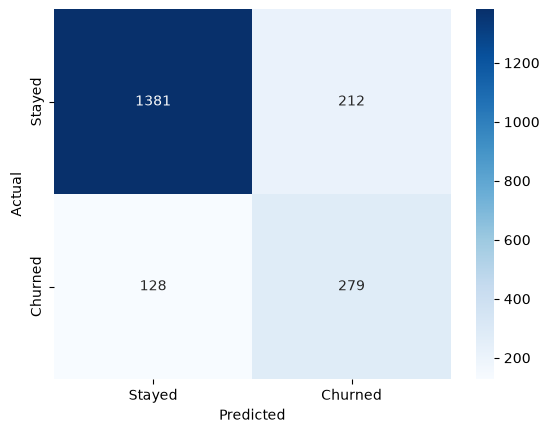

In [92]:
best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

best_proba = probas[best_name]
best_pred = (best_proba >= 0.5).astype(int)

print(classification_report(y_test, best_pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

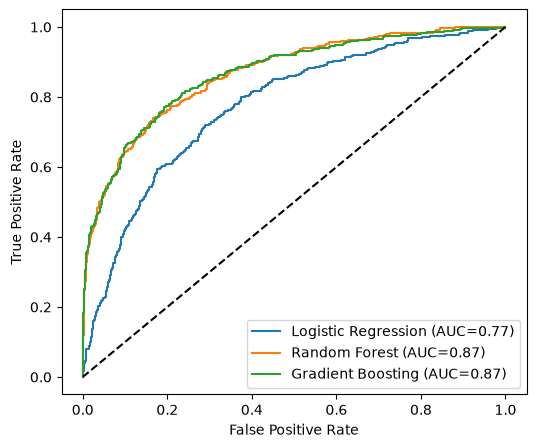

In [93]:
plt.figure(figsize=(6, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(); plt.show()

In [94]:
prec, rec, thr = precision_recall_curve(y_test, best_proba)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_t = thr[np.argmax(f1s[:-1])]
print("Best F1 threshold:", round(best_t, 3))

tuned_pred = (best_proba >= best_t).astype(int)
print(classification_report(y_test, tuned_pred, target_names=["Stayed", "Churned"]))

Best F1 threshold: 0.542
              precision    recall  f1-score   support

      Stayed       0.91      0.90      0.91      1593
     Churned       0.63      0.64      0.64       407

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



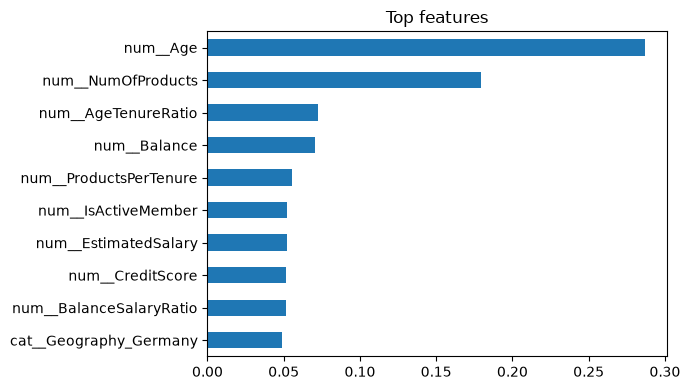

In [95]:
rf = models["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)
imp.sort_values().tail(10).plot(kind="barh", figsize=(7, 4), title="Top features")
plt.tight_layout(); plt.show()

In [96]:
new_customer = pd.DataFrame([{
    "CreditScore": 600, "Geography": "Germany", "Gender": "Female",
    "Age": 45, "Tenure": 3, "Balance": 120000, "NumOfProducts": 1,
    "HasCrCard": 1, "IsActiveMember": 0, "EstimatedSalary": 60000,
}])

# Apply the same feature engineering as Step 5
new_customer["BalanceSalaryRatio"] = new_customer["Balance"] / (new_customer["EstimatedSalary"] + 1)
new_customer["IsZeroBalance"] = (new_customer["Balance"] == 0).astype(int)
new_customer["AgeTenureRatio"] = new_customer["Tenure"] / new_customer["Age"]
new_customer["ProductsPerTenure"] = new_customer["NumOfProducts"] / (new_customer["Tenure"] + 1)

new_customer = new_customer[X.columns]  # same column order
prob = best_model.predict_proba(new_customer)[0, 1]
print(f"Churn probability: {prob:.1%}")

Churn probability: 85.2%


In [97]:
joblib.dump(best_model, "churn_model.pkl", compress=3)

# Later:
# model = joblib.load("churn_model.pkl")
# model.predict_proba(new_customer)

['churn_model.pkl']